In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

df = pd.read_csv("../Data/telco_churn_cleaned.csv")

# Target and features
y = df["Churn_flag"]
X = df.drop(columns=["customerID", "Churn", "Churn_flag"])

# Convert text columns to numbers (one-hot encoding)
X = pd.get_dummies(X, drop_first=True)
print(X.shape)

(7043, 31)


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))   # both about 0.265

(5634, 31) (1409, 31)
0.265 0.265


In [3]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services", "avg_monthly_spend"]

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_s, y_train)
lr_pred = lr.predict(X_test_s)

print("Accuracy :", round(accuracy_score(y_test, lr_pred), 3))
print("Precision:", round(precision_score(y_test, lr_pred), 3))
print("Recall   :", round(recall_score(y_test, lr_pred), 3))
print("F1       :", round(f1_score(y_test, lr_pred), 3))

Accuracy : 0.798
Precision: 0.654
Recall   : 0.511
F1       : 0.574


In [4]:
rf = RandomForestClassifier(n_estimators=200, max_depth=8,
                            random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall   :", round(recall_score(y_test, rf_pred), 3))
print("F1       :", round(f1_score(y_test, rf_pred), 3))

Accuracy : 0.801
Precision: 0.672
Recall   : 0.492
F1       : 0.568


In [5]:
rf_bal = RandomForestClassifier(n_estimators=200, max_depth=8,
                                class_weight="balanced", random_state=42)
rf_bal.fit(X_train, y_train)
bal_pred = rf_bal.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, bal_pred), 3))
print("Precision:", round(precision_score(y_test, bal_pred), 3))
print("Recall   :", round(recall_score(y_test, bal_pred), 3))
print("F1       :", round(f1_score(y_test, bal_pred), 3))

Accuracy : 0.764
Precision: 0.539
Recall   : 0.775
F1       : 0.636


                      Model  Accuracy  Precision  Recall     F1
0       Logistic Regression     0.798      0.654   0.511  0.574
1             Random Forest     0.801      0.672   0.492  0.568
2  Random Forest (balanced)     0.764      0.539   0.775  0.636


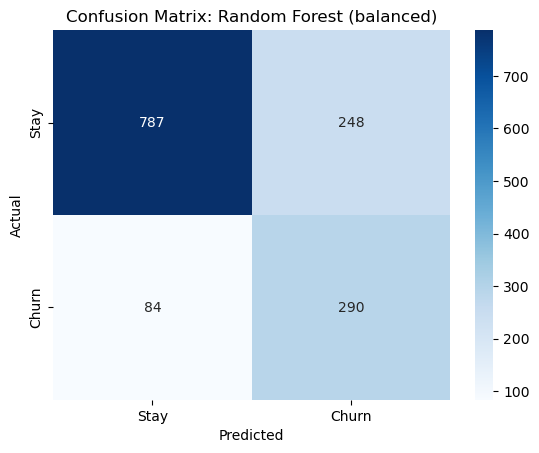

In [6]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "Random Forest (balanced)"],
    "Accuracy":  [accuracy_score(y_test, p) for p in (lr_pred, rf_pred, bal_pred)],
    "Precision": [precision_score(y_test, p) for p in (lr_pred, rf_pred, bal_pred)],
    "Recall":    [recall_score(y_test, p) for p in (lr_pred, rf_pred, bal_pred)],
    "F1":        [f1_score(y_test, p) for p in (lr_pred, rf_pred, bal_pred)],
}).round(3)
print(results)

cm = confusion_matrix(y_test, bal_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
plt.title("Confusion Matrix: Random Forest (balanced)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("../screenshots/model_01_confusion_matrix.png", bbox_inches="tight")
plt.show()

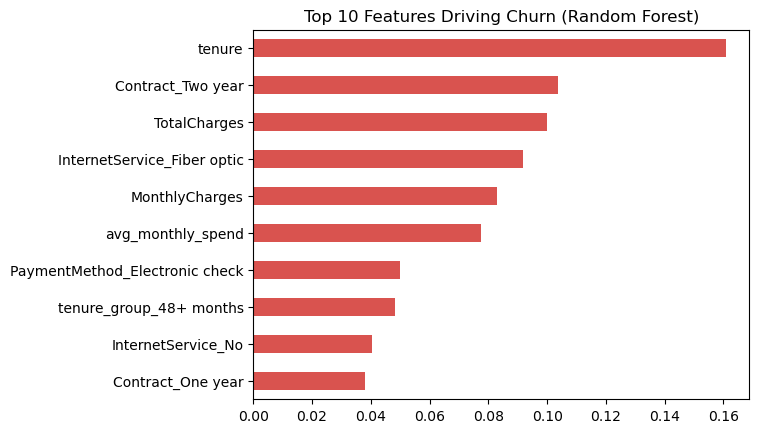

tenure                            0.161
Contract_Two year                 0.104
TotalCharges                      0.100
InternetService_Fiber optic       0.092
MonthlyCharges                    0.083
avg_monthly_spend                 0.077
PaymentMethod_Electronic check    0.050
tenure_group_48+ months           0.048
InternetService_No                0.040
Contract_One year                 0.038
dtype: float64


In [7]:
imp = pd.Series(rf_bal.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", color="#D9534F")
plt.title("Top 10 Features Driving Churn (Random Forest)")
plt.savefig("../screenshots/model_02_feature_importance.png", bbox_inches="tight")
plt.show()
print(imp.round(3))

In [2]:
   import pandas as pd
   df = pd.read_csv("../Data/telco_churn_cleaned.csv")
   df.to_csv("../Data/telco_for_tableau.csv", index=False)